# 02: Strategy Walkthrough on a Single Pair

Here I take **PEP/TGT**, my top-ranked Consumer pair (the classic KO/PEP
did not pass the cointegration gate on this training window), and follow
it through every layer of the system:

1. the static OLS hedge ratio vs the **Kalman filter's dynamic hedge ratio**
2. the spread and its **z-score**, built from trailing windows only
3. the **HMM regime gate**
4. the trades the backtester actually took in the test year

In [1]:
# Setup: make src importable and load shared inputs
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks"
                       else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from src import (universe, cointegration, kalman_hedge, regime_detector,
                 signal_generator, backtest, report, config)

prices = universe.download_universe()
splits = universe.load_splits()
stocks = prices[universe.stock_columns(prices)]
vix = prices[config.VIX_TICKER]
train = universe.get_split(stocks, "train")
print("data:", prices.shape, "| splits:", splits)

data: (1257, 41) | splits: {'train': ['2021-06-11', '2024-06-10'], 'validation': ['2024-06-11', '2025-06-11'], 'test': ['2025-06-12', '2026-06-11']}


In [2]:
pairs = cointegration.select_pairs(train)
pair = pairs[(pairs.sector == "Consumer")].iloc[0]
params = json.loads(config.TUNED_PARAMS_JSON.read_text())
delta, center, window = (params["delta"], params["zscore_center"],
                         params["zscore_window"])
y_tkr, x_tkr = pair["y"], pair["x"]
print(f"pair: {y_tkr}/{x_tkr}, static beta={pair['beta']:.3f}, "
      f"half-life={pair['half_life']:.0f}d")
print(f"frozen params (tuned on validation): delta={delta:.0e}, "
      f"center='{center}', window={window}")

pair: PEP/TGT, static beta=-0.203, half-life=21d
frozen params (tuned on validation): delta=1e-04, center='rolling', window=20


## Dynamic vs static hedge ratio

The OLS beta is a single number estimated once over three years, so it
assumes the hedge relationship never changes. The Kalman filter instead
treats [beta, alpha] as a slowly drifting state and updates it each day
from that day's prices, using **filtered** estimates only. I never use
the Kalman smoother here: it conditions every day's estimate on the whole
sample including the future, which makes its smooth, attractive state
paths unusable for trading.

Two noise settings make or break this filter, and I calibrate both
instead of using textbook defaults:

- Observation noise **R**: I set it to the variance of the train OLS
  residual, which is how far this pair typically strays from its
  equilibrium. With the common default R = 1e-3 on dollar prices, the
  filter believes prices fit the model to within a few cents, absorbs
  every dislocation into the state, and leaves a "spread" that is white
  measurement noise. I hit exactly this failure while building the
  project; the tell-tale diagnostic was the spread half-life collapsing
  to roughly zero days while the OLS residual half-life was 25 days.
- Process noise **Q**: I scale the beta component by 1/scale(x)^2.
  Beta multiplies the price of x, so an unscaled random-walk step on beta
  moves the prediction by dollars per day when x trades at $800, and the
  state tracks dislocations through beta no matter how small delta is.
  After scaling, delta means the same thing for every pair: the fraction
  of observation variance the state may absorb per day.

manual vs pykalman max diff: 2.13e-14


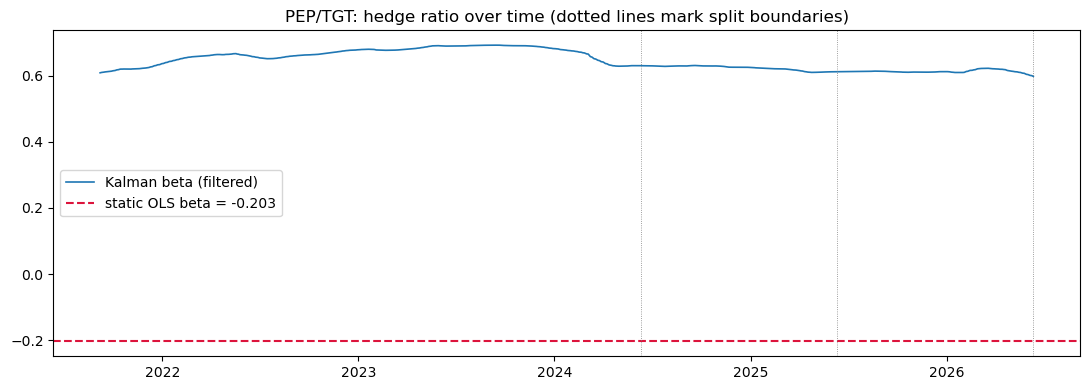

In [3]:
y_full, x_full = stocks[y_tkr], stocks[x_tkr]
kf = kalman_hedge.kalman_filter_manual(y_full, x_full, delta,
                                       obs_var=pair["resid_var"])
# I implemented the filter twice; pykalman gives identical output (asserted):
print("manual vs pykalman max diff:",
      f"{kalman_hedge.self_test(train[y_tkr], train[x_tkr], delta, pair['resid_var']):.2e}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(kf["beta"].iloc[60:], lw=1.2, label="Kalman beta (filtered)")
ax.axhline(pair["beta"], color="crimson", ls="--",
           label=f"static OLS beta = {pair['beta']:.3f}")
for name, (s, e) in splits.items():
    ax.axvline(pd.Timestamp(e), color="gray", lw=0.6, ls=":")
ax.legend(); ax.set_title(f"{y_tkr}/{x_tkr}: hedge ratio over time "
                          "(dotted lines mark split boundaries)")
plt.tight_layout(); plt.show()

## The spread and its z-score

The tradeable spread is the residual under the *current filtered state*:
`spread_t = y_t - beta_t * x_t - alpha_t`. I can compute this at each
day's close using only data up to that close, so it carries no future
information.

For the z-score I use an **expanding window for the first 60
observations, then a rolling window**. The expanding start matters
because a rolling standard deviation estimated from the first three or
four observations is so noisy that it produces meaningless z-values of 5
or 10 on day three, which would either trigger nonsense trades or force
me to discard the early period entirely.

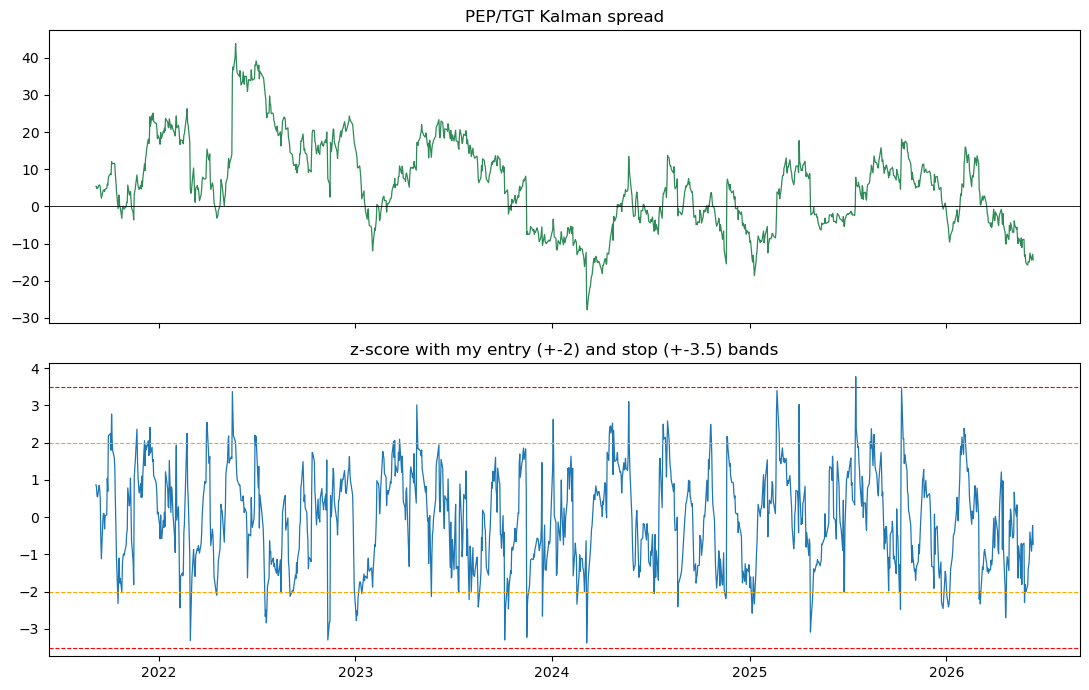

In [4]:
z = signal_generator.zscore(kf["spread"], center=center, window=window)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(kf["spread"].iloc[60:], lw=0.9, color="seagreen")
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set_title(f"{y_tkr}/{x_tkr} Kalman spread")
axes[1].plot(z.iloc[60:], lw=0.9)
for lvl, c_ in [(2, "orange"), (-2, "orange"), (3.5, "red"), (-3.5, "red")]:
    axes[1].axhline(lvl, color=c_, lw=0.8, ls="--")
axes[1].set_title("z-score with my entry (+-2) and stop (+-3.5) bands")
plt.tight_layout(); plt.show()

## The regime gate

Mean reversion is conditional: during stress periods correlations break
and spreads trend instead of reverting. I fit a 2-state Gaussian HMM on
**train-period features** (spread volatility, short and long return
correlations, VIX, spread momentum, all from trailing windows) and only
allow new entries when the model says the current day is in the
mean-reverting state.

Out of sample I classify each day with the *forward algorithm*: the state
probability at day t conditions only on observations up to t. I wrote
that recursion explicitly instead of calling `model.predict`, because
`predict` returns the Viterbi path, which chooses each day's state using
the entire series including the future. A regime gate built on Viterbi
states leaks information and makes the backtest look better than live
trading could ever be.

state labels: {0: 'mean_reverting', 1: 'trending'}
fraction of days mean-reverting: 78.3%


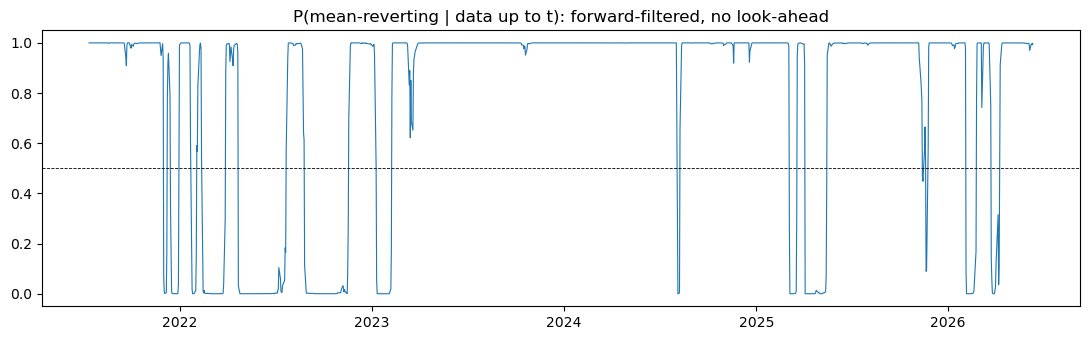

In [5]:
feats = regime_detector.build_features(y_full, x_full, kf["spread"], vix)
det = regime_detector.RegimeDetector().fit(feats.loc[:splits["train"][1]])
regimes = det.filtered_regimes(feats)
probs = det.filtered_probabilities(feats)
print(f"state labels: {det.state_labels}")
print(f"fraction of days mean-reverting: {regimes.mean():.1%}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(probs, lw=0.8)
ax.set_title("P(mean-reverting | data up to t): forward-filtered, no look-ahead")
ax.axhline(0.5, color="k", lw=0.6, ls="--")
plt.tight_layout(); plt.show()

## Trades on this pair in the test year

The backtester makes decisions at one close and fills at the **next**
close, with 5 bps cost plus 2 bps slippage per side. Entries are
re-confirmed at the fill bar: if the dislocation vanished overnight, the
order is cancelled instead of filled. I added that rule after measuring
that the average |z| decayed from 2.55 at decision time to 0.77 at fill
time, which means that without re-confirmation I was systematically
buying one-day spikes after they had already snapped back.

Below is every trade the backtester took on this pair out of sample.

,pair,direction,entry_date,exit_date,entry_z,exit_z,pnl_dollars,pnl_bps,holding_days,exit_reason
2,PEP/TGT,short,2025-07-18,2025-08-01,2.36,0.38,221.08,69.10,14,signal
9,PEP/TGT,short,2025-10-13,2025-10-28,2.09,-0.77,702.79,219.13,15,signal
18,PEP/TGT,long,2026-03-06,2026-04-06,-2.02,-0.37,-538.64,-166.70,31,signal
19,PEP/TGT,long,2026-04-22,2026-05-01,-2.25,0.11,595.70,185.40,9,signal


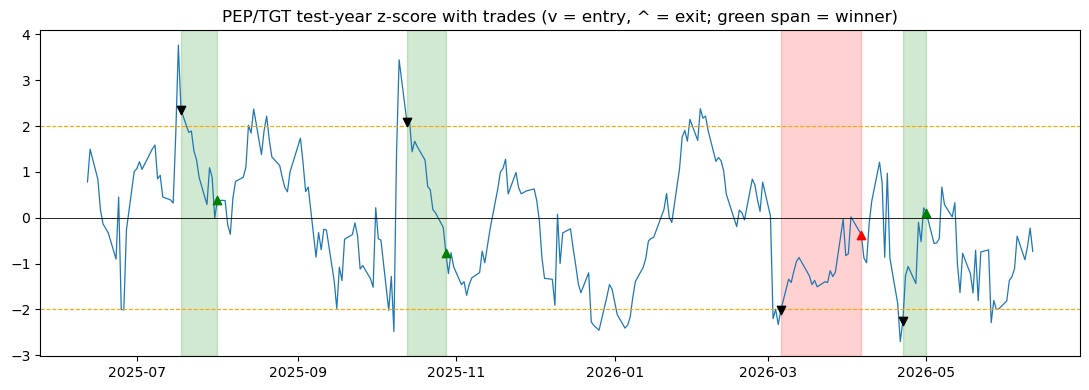

In [6]:
trades = pd.read_csv(config.RESULTS_DIR / "trades_test.csv",
                     parse_dates=["entry_date", "exit_date"])
mine = trades[trades.pair == f"{y_tkr}/{x_tkr}"]
display(mine.round(2))

start, end = splits["test"]
fig, ax = plt.subplots(figsize=(11, 4))
zt = z.loc[start:end]
ax.plot(zt, lw=0.9)
for _, t in mine.iterrows():
    col = "green" if t.pnl_dollars > 0 else "red"
    ax.axvspan(t.entry_date, t.exit_date, color=col, alpha=0.18)
    ax.scatter([t.entry_date], [t.entry_z], marker="v", color="k", zorder=5)
    ax.scatter([t.exit_date], [t.exit_z], marker="^", color=col, zorder=5)
for lvl in (2, -2): ax.axhline(lvl, color="orange", lw=0.8, ls="--")
ax.axhline(0, color="k", lw=0.6)
ax.set_title(f"{y_tkr}/{x_tkr} test-year z-score with trades "
             "(v = entry, ^ = exit; green span = winner)")
plt.tight_layout(); plt.show()